In [12]:
import pandas as pd
from db_queries import get_location_metadata
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from tqdm import tqdm
import numpy as np
from matplotlib.ticker import MaxNLocator
from pathlib import Path
import yaml

# Set paths ####################################################################
RAW_DATA_PATH = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/training_data/2026_09_13.01/data.parquet"
GBD_FILE = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/input/gbd_prevalence/gbd_mean_neonatal_mortality_prevalence.parquet"
INFERENCE_FILE_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_14.01/ssp245.parquet"  # Consumption merged on birth year
RESULTS_09_14 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_14.02/"  # .01 is the input spec; .02 is the fit

RESULTS_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_21.02/"
RESULTS_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_22.02/"
RESULTS_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.02/"  # birth_year dropped, consumption_median_RT rescaled to $/day
RESULTS_09_24 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_23.03/"  # birth_year dropped, consumption_median_RT, climate variables included
RESULTS_09_25 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/models/2026_09_25.01/"  # final specification, sex_id modified


INFERENCE_FILE_09_21 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.01/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
INFERENCE_FILE_09_22 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_22.02/ssp245.parquet"  # Inclusion of consumption_pd_national_median (logged)
INFERENCE_FILE_09_23 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.01/ssp245.parquet"  # model 2026_09_23.02: consumption_median_RT (LDI based), no birth_year
INFERENCE_FILE_09_24 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_23.02/ssp245.parquet"  # model 2026_09_24: birth_year dropped, consumption_median_RT, climate variables included
INFERENCE_FILE_09_25 = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_25.02/ssp245.parquet"  # final specification, sex_id modified
PLOT_OUTPUT = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/"


df_raw = pd.read_parquet(RAW_DATA_PATH)

# Add location names
locs = get_location_metadata(location_set_id=39, release_id=16)

df_raw = df_raw.merge(
    locs[["location_id", "location_name", "level", "super_region_name"]],
    on="location_id",
    how="left",
)

df_raw.head()

,year_start,year_end,nid,survey_name,int_year,int_month,sex_id,mothers_age_year,aod_months,age_month,...,year_id,age_group_id,int_birth_year_diff_months,log_consumption_pd,sdi,consumption_pd_national_median,consumption_median_RT,location_name,level,super_region_name
0,2009,2010,13109,DHS_MIS,None,None,2,None,0,0,...,2009,42,0,-0.245692,0.318291,2.179549,2.361256,Uganda,3,Sub-Saharan Africa
1,2022,2022,538795,None,2022,5,2,18,0,0,...,2021,42,11,1.312609,0.447416,3.220460,3.404259,United Republic of Tanzania,3,Sub-Saharan Africa
2,2017,2017,353526,None,2017,4,1,20,0,0,...,2017,42,0,2.448691,0.373539,3.087602,4.210878,Senegal,3,Sub-Saharan Africa
3,2019,2021,467681,DHS,None,None,1,None,0,0,...,2020,42,2,1.619791,0.583046,4.671741,5.111802,India,3,South Asia
4,2000,2000,19156,None,2000,2,2,24,0,0,...,1999,42,2,-0.227447,0.340183,1.772798,2.106530,Cambodia,3,"Southeast Asia, East Asia, and Oceania"


60 countries have a fitted random intercept in 2026_09_25.01
survey points: 49 country-years with >= 100 births (Angola, Namibia, Rwanda)
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/predictions_09_25_four_countries.pdf


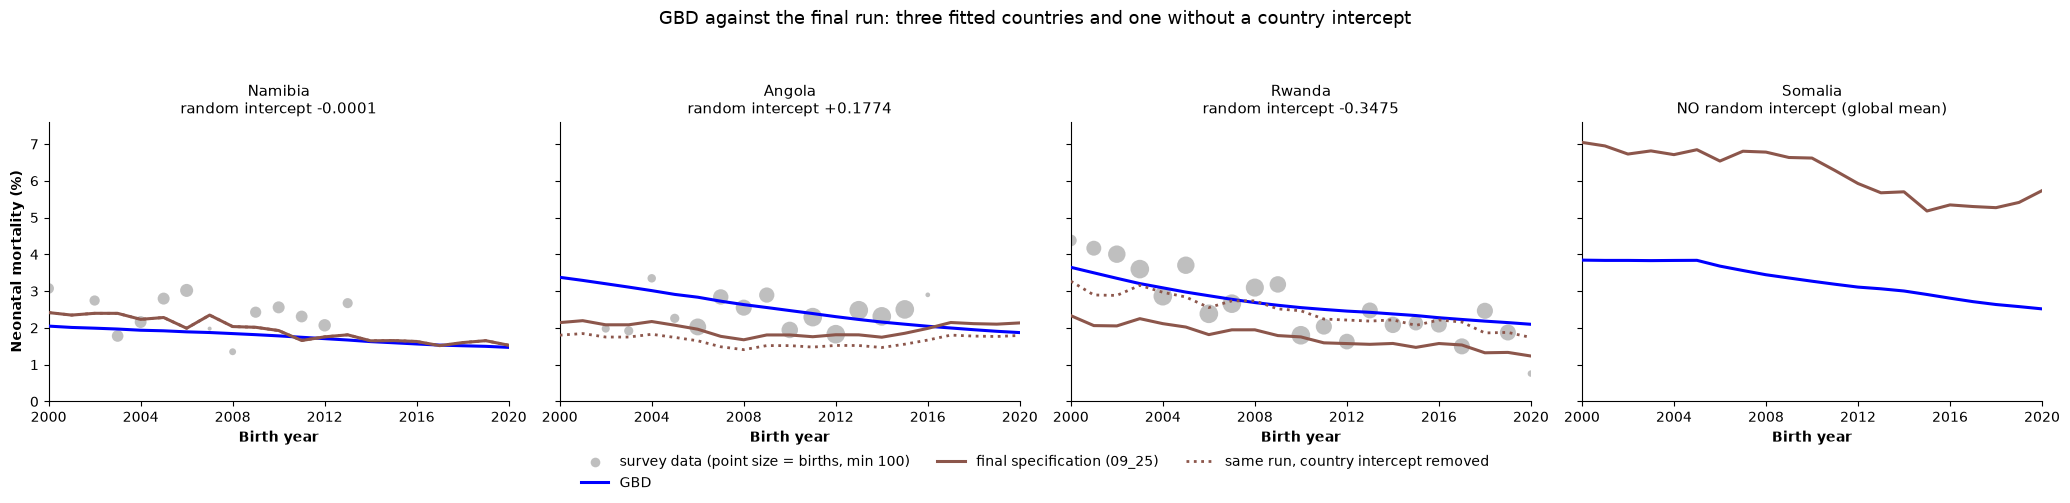


2000 -> 2020 (%):
               gbd_first  gbd_last  i0925_first  i0925_last  i0925_no_re_first  i0925_no_re_last
location_name                                                                                   
Namibia             2.05      1.47         2.42        1.53               2.42              1.53
Angola              3.38      1.87         2.14        2.14               1.80              1.79
Rwanda              3.65      2.10         2.33        1.24               3.27              1.74
Somalia             3.84      2.52         7.04        5.73               7.04              5.73


In [13]:
# GBD against the final run, three focus countries plus one without a ranef ##
# Same shape as predictions_four_runs_three_countries, cut down to two series:
# GBD and the 2026_09_25.01 fit. Both are sex-averaged, and the inference run
# is averaged over draws.
#
# The fourth panel is the point of the figure. Somalia is Sub-Saharan African
# and appears in the results, but it has no DHS survey in the training data, so
# the model never fitted it a country intercept. Its prediction is the global
# fixed intercept plus covariates, while the other three carry their own
# offset. Each panel says which it is, read from the fit rather than hardcoded.
from scipy.special import expit, logit

R5_COUNTRIES = ["Namibia", "Angola", "Rwanda", "Somalia"]
R5_YEARS = (2000, 2020)
R5_SERIES = {
    "gbd": (GBD_FILE, False, "blue", "GBD"),
    "i0925": (INFERENCE_FILE_09_25, True, "#8c564b", "final specification (09_25)"),
}
R5_RANEF = Path(RESULTS_09_25) / "base_model_ranef.parquet"


def _r5_mean_draw(frame):
    """Inference files carry either draw columns or a long `draw` column."""
    draw_cols = [c for c in frame.columns if c.startswith("draw_")]
    if draw_cols:
        out = frame[[c for c in frame.columns if "draw_" not in c]].copy()
        out["prevalence"] = frame[draw_cols].mean(axis=1)
        return out
    value_col = "value" if "value" in frame.columns else "prevalence"
    keys = [c for c in ("location_id", "year_id", "sex_id") if c in frame.columns]
    return (
        frame.groupby(keys, as_index=False)[value_col]
        .mean()
        .rename(columns={value_col: "prevalence"})
    )


_r5_key = ["location_id", "year_id", "sex_id"]
r5 = None
for col, (path, is_draws, _c, _l) in R5_SERIES.items():
    f = pd.read_parquet(path).reset_index()
    f = (
        _r5_mean_draw(f).rename(columns={"prevalence": col})
        if is_draws
        else f.rename(columns={"gbd_mean_prevalence": col})
    )
    keys = [k for k in _r5_key if k in f.columns]
    f = f[keys + [col]]
    r5 = f if r5 is None else r5.merge(f, on=keys, how="inner")

r5 = (
    r5.merge(
        locs[["location_id", "location_name", "ihme_loc_id"]].drop_duplicates(
            "location_id"
        ),
        on="location_id",
        how="inner",
    )
    .query("year_id >= @R5_YEARS[0] and year_id <= @R5_YEARS[1]")
    .groupby(["location_name", "ihme_loc_id", "year_id"], as_index=False)[
        list(R5_SERIES)
    ]
    .mean()
    .sort_values("year_id")
)

# Which of these countries the model actually fitted an intercept for.
_ranef = pd.read_parquet(R5_RANEF)["offset"]
print(
    f"{_ranef.shape[0]} countries have a fitted random intercept in "
    f"{Path(RESULTS_09_25).name}"
)

# The same prediction with the country intercept taken back out. The published
# value is a mean of expit() over ten income deciles, so subtracting the offset
# from a single aggregate logit is an approximation rather than a re-run of the
# decile integration. Checked against the exact integration using this model's
# own per-decile spline effects: the two agree to within 0.03% relative for
# these countries, which is far below the effect being drawn.
r5["i0925_no_re"] = expit(
    logit(r5["i0925"].clip(1e-9, 1 - 1e-9)) - r5["ihme_loc_id"].map(_ranef).fillna(0.0)
)

# Observed survey rates behind the lines: mean neonatal_mortality by country
# and birth year, straight from the training data. Years with very few births
# are dropped rather than drawn small - Namibia has a birth year with n=4 and a
# 25% rate, which is noise but would still set the shared y limit.
R5_MIN_BIRTHS = 100
r5_obs = (
    df_raw[df_raw["location_name"].isin(R5_COUNTRIES)]
    .groupby(["location_name", "birth_year"], observed=True)
    .agg(rate=("neonatal_mortality", "mean"), n=("neonatal_mortality", "size"))
    .reset_index()
    .query(
        "n >= @R5_MIN_BIRTHS and birth_year >= @R5_YEARS[0] "
        "and birth_year <= @R5_YEARS[1]"
    )
)
print(
    f"survey points: {len(r5_obs)} country-years with >= {R5_MIN_BIRTHS} births "
    f"({', '.join(sorted(r5_obs['location_name'].unique()))})"
)

_r5_focus = r5[r5["location_name"].isin(R5_COUNTRIES)]
R5_YMAX = (
    100
    * float(
        max(
            _r5_focus[[*R5_SERIES, "i0925_no_re"]].to_numpy().max(),
            r5_obs["rate"].max(),
        )
    )
    * 1.08
)

fig, axes = plt.subplots(
    ncols=len(R5_COUNTRIES), figsize=(5.2 * len(R5_COUNTRIES), 5.0), sharey=True
)
axes = np.atleast_1d(axes)
handles, labels = [], []
for ax, country in zip(axes, R5_COUNTRIES):
    block = r5[r5["location_name"] == country].sort_values("year_id")
    loc = block["ihme_loc_id"].iloc[0]
    obs = r5_obs[r5_obs["location_name"] == country]
    if len(obs):
        ax.scatter(
            obs["birth_year"],
            100 * obs["rate"],
            s=np.clip(obs["n"] / 12, 8, 180),
            color="0.55",
            alpha=0.55,
            linewidths=0,
            zorder=1,
            label=f"survey data (point size = births, min {R5_MIN_BIRTHS})",
        )
    for col, (_p, _d, colour, label) in R5_SERIES.items():
        ax.plot(
            block["year_id"],
            100 * block[col],
            color=colour,
            lw=2.2,
            zorder=3,
            label=label,
        )
    # Dotted: the same run with this country's intercept removed. Drawn only
    # where there is one to remove, so Somalia's single line is unambiguous.
    if loc in _ranef.index:
        ax.plot(
            block["year_id"],
            100 * block["i0925_no_re"],
            color=R5_SERIES["i0925"][2],
            lw=2.0,
            ls=":",
            zorder=4,
            label="same run, country intercept removed",
        )
    ax.set_xlim(*R5_YEARS)
    ax.set_ylim(0, R5_YMAX)
    ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
    ax.set_xlabel("Birth year", fontweight="bold")
    note = (
        f"random intercept {_ranef[loc]:+.4f}"
        if loc in _ranef.index
        else "NO random intercept (global mean)"
    )
    ax.set_title(f"{country}\n{note}", fontsize=10.5)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if not handles:
        handles, labels = ax.get_legend_handles_labels()
axes[0].set_ylabel("Neonatal mortality (%)", fontweight="bold")
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=10, frameon=False)
fig.suptitle(
    "GBD against the final run: three fitted countries and one without a "
    "country intercept",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0.08, 1, 0.93))
plot_path = f"{PLOT_OUTPUT}predictions_09_25_four_countries.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

print(f"\n{R5_YEARS[0]} -> {R5_YEARS[1]} (%):")
_ends = (
    _r5_focus.groupby("location_name")
    .agg(
        **{
            f"{c}_{w}": (c, w)
            for c in [*R5_SERIES, "i0925_no_re"]
            for w in ("first", "last")
        }
    )
    .loc[R5_COUNTRIES]
)
print((100 * _ends).round(2).to_string())

Rwanda 2000-2050, sex 1, age 42; SSA band from 46 countries' own SDI
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/rwanda_residual_pipeline.pdf


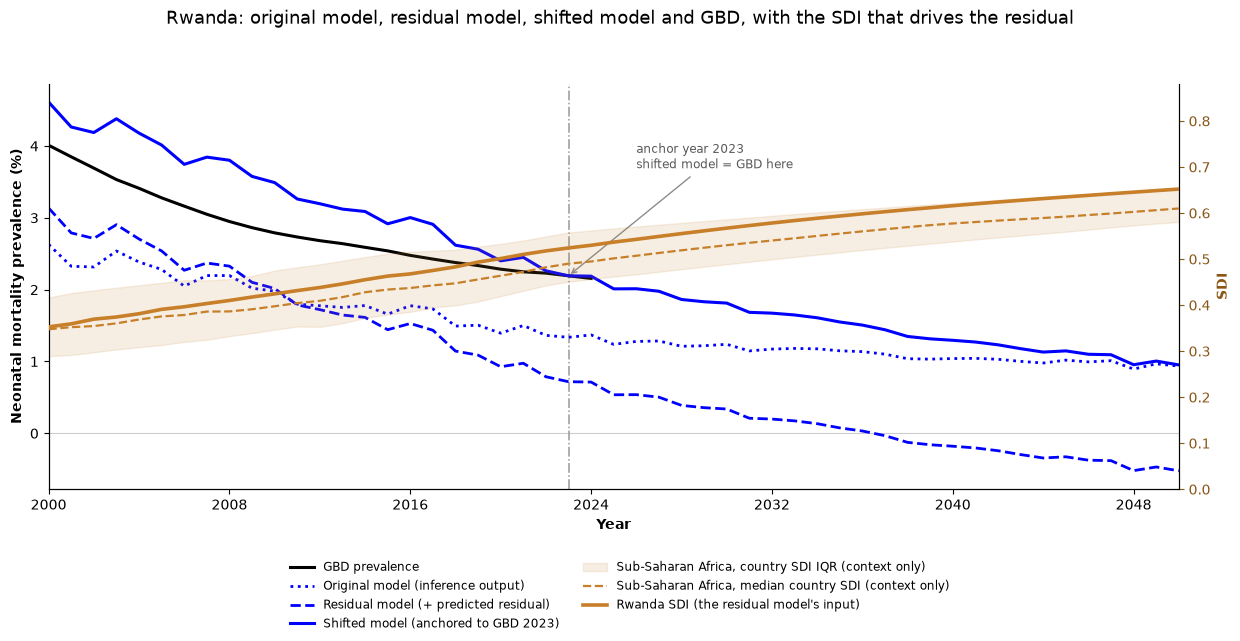


(%)   gbd_value  model_value  residual_model_value  adjusted_model_value     SDI
2000       4.010       2.630       3.137       4.611  0.3527
2010       2.791       1.979       2.016       3.490  0.4244
2023       2.193       1.337       0.718       2.193  0.5242
2035         nan       1.149       0.075       1.550  0.5935
2050         nan       0.935      -0.522       0.952  0.6520


In [14]:
# Rwanda: the four prevalence series and the SDI that drives the residual ####
# Everything the residual step produces for one location/sex/age, read from
# sev_means.parquet, which is what neonatal_mortality_prevalence_plots.pdf is
# drawn from. Line styles match that pdf so the two can be read together.
#
# NOTE ON "Sub-Saharan Africa's SDI": there is no such series. The SDI file is
# country level only - location 166 is absent - and the residual model never
# uses a super-region SDI. It uses each country's OWN SDI together with a slope
# shared across the super region. The SSA band below is therefore a summary I
# compute across the 44 SSA countries for context, not a model input.
import xarray as xr

RW_RESULTS = "/mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/results/2026_09_25.02/sev_means.parquet"
PAST_SDI = "/mnt/share/forecasting/data/32/past/sdi/past_sdi_s130v89/sdi.nc"
FUTURE_SDI = "/mnt/share/forecasting/data/32/future/sdi/future_sdi_s130v89/sdi.nc"
FUTURE_SDI_SCENARIO = 130
RW_LOC, RW_SEX, RW_AGE = 185, 1, 42
RW_YEARS = (2000, 2050)
LAST_GBD_YEAR = 2023


def load_sdi():
    """Past and future SDI, draw-averaged, matching the residual step."""
    past = xr.open_dataset(PAST_SDI).to_dataframe().reset_index()
    past = past.groupby(["location_id", "year_id"], as_index=False)["draws"].mean()
    fut = xr.open_dataset(FUTURE_SDI).to_dataframe().reset_index()
    fut = fut[fut["scenario"] == FUTURE_SDI_SCENARIO]
    fut = fut.groupby(["location_id", "year_id"], as_index=False)["draws"].mean()
    out = pd.concat([past, fut]).rename(columns={"draws": "sdi"})
    return out.drop_duplicates(["location_id", "year_id"])


sdi_all = load_sdi()
rw = (
    pd.read_parquet(RW_RESULTS)
    .xs((RW_LOC, RW_SEX, RW_AGE), level=("location_id", "sex_id", "age_group_id"))
    .sort_index()
    .loc[RW_YEARS[0] : RW_YEARS[1]]
)
rw["sdi"] = rw.index.map(
    sdi_all.set_index(["location_id", "year_id"])["sdi"].xs(RW_LOC)
)
rw["predicted_residual"] = rw["residual_model_value"] - rw["model_value"]

# SSA context band: the spread of member countries' own SDI, not an input
_ssa_ids = locs.query("super_region_name == 'Sub-Saharan Africa' and level == 3")[
    "location_id"
].unique()
ssa = (
    sdi_all[sdi_all["location_id"].isin(_ssa_ids)]
    .query("year_id >= @RW_YEARS[0] and year_id <= @RW_YEARS[1]")
    .groupby("year_id")["sdi"]
    .agg(lo=lambda s: s.quantile(0.25), mid="median", hi=lambda s: s.quantile(0.75))
)
print(
    f"Rwanda {RW_YEARS[0]}-{RW_YEARS[1]}, sex {RW_SEX}, age {RW_AGE}; "
    f"SSA band from {len(_ssa_ids)} countries' own SDI"
)

RW_STYLE = [
    ("gbd_value", "black", "-", 2.2, "GBD prevalence"),
    ("model_value", "blue", ":", 2.0, "Original model (inference output)"),
    (
        "residual_model_value",
        "blue",
        "--",
        2.0,
        "Residual model (+ predicted residual)",
    ),
    ("adjusted_model_value", "blue", "-", 2.2, "Shifted model (anchored to GBD 2023)"),
]

fig, ax = plt.subplots(figsize=(12.5, 6.4))
for col, colour, ls, lw, label in RW_STYLE:
    ax.plot(rw.index, 100 * rw[col], color=colour, ls=ls, lw=lw, label=label, zorder=4)
ax.axvline(LAST_GBD_YEAR, color="0.6", lw=1.1, ls="-.", zorder=2)
ax.annotate(
    f"anchor year {LAST_GBD_YEAR}\nshifted model = GBD here",
    xy=(LAST_GBD_YEAR, 100 * rw.loc[LAST_GBD_YEAR, "gbd_value"]),
    xytext=(LAST_GBD_YEAR + 3, 100 * rw["gbd_value"].max() * 0.92),
    fontsize=8.5,
    color="0.35",
    arrowprops=dict(arrowstyle="->", color="0.55", lw=1),
)
ax.axhline(0, color="0.8", lw=0.8, zorder=1)
ax.set_xlim(*RW_YEARS)
ax.xaxis.set_major_locator(MaxNLocator(8, integer=True))
ax.set_xlabel("Year", fontweight="bold")
ax.set_ylabel("Neonatal mortality prevalence (%)", fontweight="bold")
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)

# SDI on the right axis: Rwanda's own, plus where its super region sits
ax2 = ax.twinx()
ax2.fill_between(
    ssa.index,
    ssa["lo"],
    ssa["hi"],
    color="#c77f2a",
    alpha=0.13,
    zorder=1,
    label="Sub-Saharan Africa, country SDI IQR (context only)",
)
ax2.plot(
    ssa.index,
    ssa["mid"],
    color="#c77f2a",
    lw=1.6,
    ls="--",
    zorder=3,
    label="Sub-Saharan Africa, median country SDI (context only)",
)
ax2.plot(
    rw.index,
    rw["sdi"],
    color="#c77f2a",
    lw=2.6,
    zorder=4,
    label="Rwanda SDI (the residual model's input)",
)
ax2.set_ylabel("SDI", fontweight="bold", color="#8a5616")
ax2.tick_params(axis="y", colors="#8a5616")
ax2.set_ylim(0, max(ssa["hi"].max(), rw["sdi"].max()) * 1.35)
ax2.spines["top"].set_visible(False)

h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="lower center", ncol=2, fontsize=8.5, frameon=False)
fig.suptitle(
    "Rwanda: original model, residual model, shifted model and GBD, with the SDI "
    "that drives the residual",
    fontsize=13,
)
fig.tight_layout(rect=(0, 0.14, 1, 0.94))
plot_path = f"{PLOT_OUTPUT}rwanda_residual_pipeline.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

print("\n(%)  " + "  ".join(f"{c:>10s}" for c, *_ in RW_STYLE) + f"{'SDI':>8s}")
for y in (2000, 2010, 2023, 2035, 2050):
    r = rw.loc[y]
    print(
        f"{y}  "
        + "  ".join(f"{100 * r[c]:10.3f}" for c, *_ in RW_STYLE)
        + f"{r['sdi']:8.4f}"
    )

/tmp/ipykernel_656565/386907762.py:37: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit()


pooled fit: 22,704 rows, 473 locations, 946 location/sex strata, 7 super regions
  SSA raw -4.309  ->  applied -6.565 pp/SDI
Saved /mnt/team/rapidresponse/pub/population/modeling/climate_malnutrition/neonatal_mortality/plots/rwanda_residual_steps.pdf


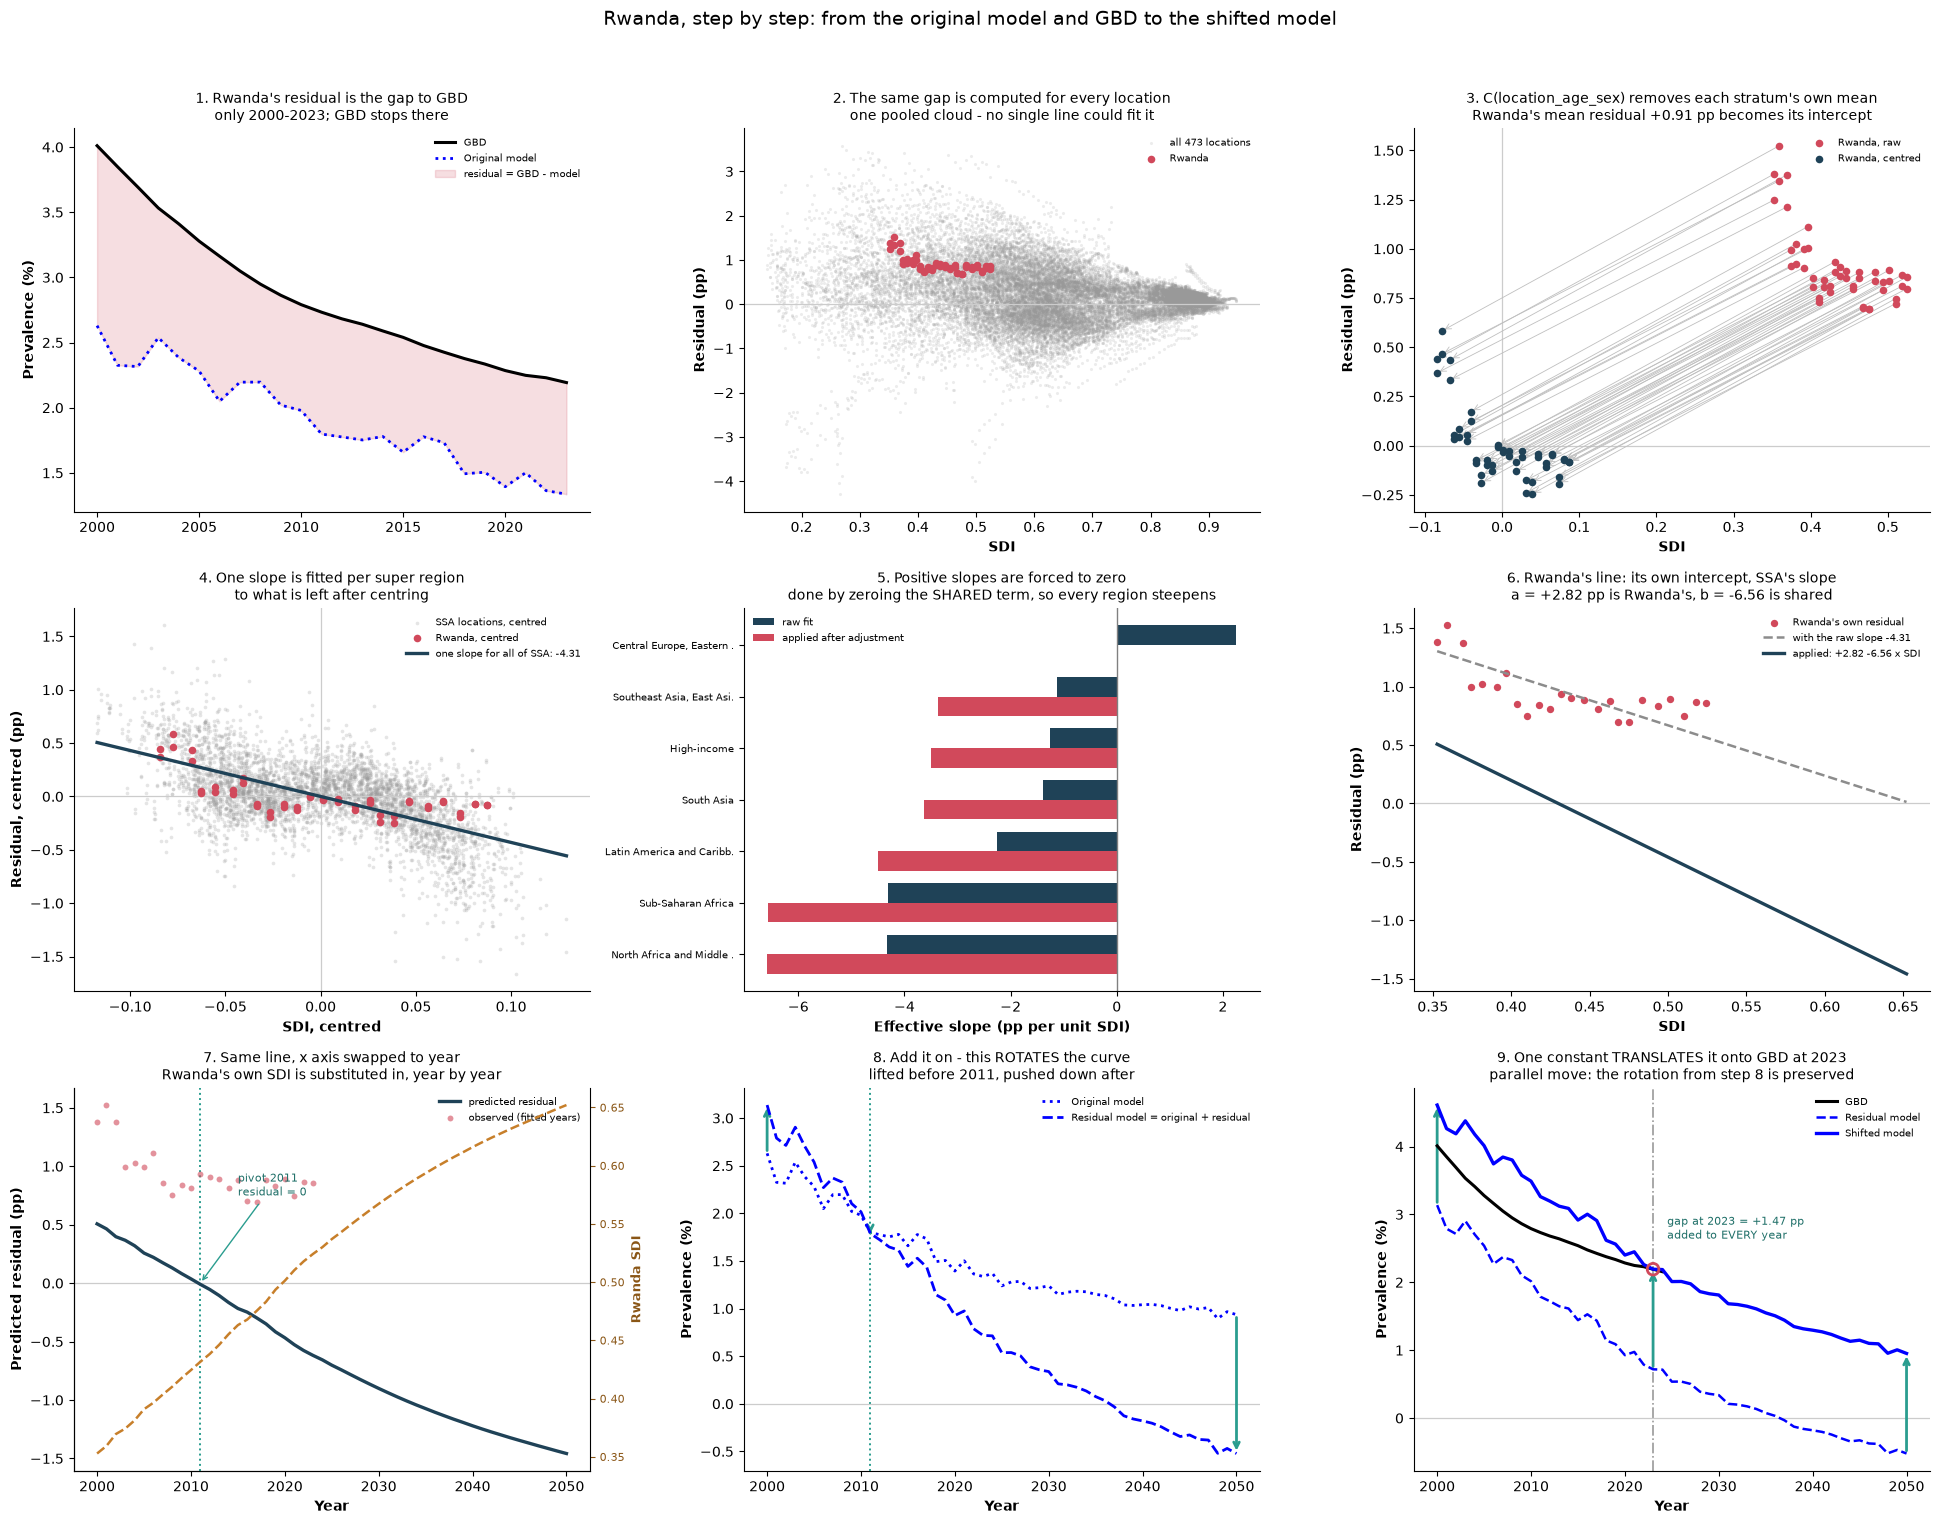


Rwanda: predicted_residual = +2.8230 -6.5649 * SDI   (pp)
  intercept from step 3 (Rwanda's mean residual): +0.910 pp
  slope raw -4.309 -> applied -6.565 pp/SDI
  pivot year 2011, constant shift +1.475 pp


In [ ]:
# The residual pipeline for Rwanda, broken into nine steps ###################
# Reuses rw / sdi_all / locs / RW_* from the cell above.
#
# The regression is refitted here from sev_means.parquet rather than taken on
# trust. That reproduces the pipeline's RAW coefficients exactly (SSA raw slope
# -4.309 pp/SDI). The slope the pipeline finally APPLIES is different, because
# adjust_sdi_slopes_non_positive rewrites the coefficients afterwards, so that
# one is recovered from the saved predicted residual instead of reimplementing
# the adjustment. Steps 5 and 6 show the two side by side.
import statsmodels.formula.api as smf

SR_SSA = "Sub-Saharan Africa"
_sr = locs[["location_id", "super_region_name"]].drop_duplicates("location_id")

# ---- assemble the pooled fit frame, exactly as the residual step does ------
pool = (
    pd.read_parquet(RW_RESULTS)
    .xs(RW_AGE, level="age_group_id")
    .reset_index()
    .merge(sdi_all, on=["location_id", "year_id"], how="left")
    .merge(_sr, on="location_id", how="left")
    .query("year_id >= @RW_YEARS[0] and year_id <= @LAST_GBD_YEAR")
    .dropna(subset=["sdi", "gbd_value", "model_value", "super_region_name"])
    .copy()
)
pool["resid"] = 100 * (pool["gbd_value"] - pool["model_value"])
pool["las"] = pool.location_id.astype(str) + "_" + pool.sex_id.astype(str)
# the per-stratum intercept is exactly a within-stratum mean, so centring by it
# is what isolates the variation the shared slope is estimated from
for _c in ("resid", "sdi"):
    pool[f"{_c}_w"] = pool[_c] - pool.groupby("las")[_c].transform("mean")

_fit = smf.ols("resid ~ 0 + sdi + sdi*C(super_region_name) + C(las)", data=pool).fit()
_b0 = float(_fit.params["sdi"])
raw_slope = {}
for _k, _v in _fit.params.items():
    if _k.startswith("sdi:C(super_region_name)"):
        raw_slope[_k.split("[")[-1].rstrip("]").replace("T.", "")] = _b0 + float(_v)
for _lvl in pool.super_region_name.unique():
    raw_slope.setdefault(_lvl, _b0)

# the slope actually applied, read back off the saved predicted residual
_appl = (
    pd.read_parquet(RW_RESULTS)
    .xs((RW_SEX, RW_AGE), level=("sex_id", "age_group_id"))
    .reset_index()
    .merge(sdi_all, on=["location_id", "year_id"], how="left")
    .merge(_sr, on="location_id", how="left")
    .dropna(subset=["sdi"])
)
_appl["pr"] = 100 * (_appl["residual_model_value"] - _appl["model_value"])
# One location at a time: predicted_residual is intercept + slope * SDI within
# a location, so pooling across locations would mix in their differing
# intercepts and understate the slope. Every location in a super region returns
# the same number, so the median is that number.
_per_loc = {
    _k: np.polyfit(_g["sdi"], _g["pr"], 1)[0]
    for _k, _g in _appl.groupby("location_id")
    if _g["sdi"].nunique() > 1
}
_appl["loc_slope"] = _appl["location_id"].map(_per_loc)
applied_slope = (
    _appl.dropna(subset=["loc_slope"])
    .groupby("super_region_name")["loc_slope"]
    .median()
    .to_dict()
)
# Rwanda's own applied line, read straight off the saved predicted residual
# (it is intercept + slope * SDI by construction, so this is exact, not a fit)
_ok = rw.dropna(subset=["sdi"])
RW_SLOPE, RW_ICEPT = np.polyfit(_ok["sdi"], _ok["predicted_residual"], 1)
RW_A, RW_B = 100 * RW_ICEPT, 100 * RW_SLOPE
print(
    f"pooled fit: {len(pool):,} rows, {pool.location_id.nunique()} locations, "
    f"{pool.las.nunique()} location/sex strata, {pool.super_region_name.nunique()} "
    f"super regions\n  SSA raw {raw_slope[SR_SSA]:+.3f}  ->  applied "
    f"{applied_slope[SR_SSA]:+.3f} pp/SDI"
)

rw["observed_residual"] = rw["gbd_value"] - rw["model_value"]
_hist = rw.loc[RW_YEARS[0] : LAST_GBD_YEAR]
_ssa_pool = pool[pool.super_region_name == SR_SSA]
_rw_pool = _ssa_pool[_ssa_pool.location_id == RW_LOC]
ZERO_YEAR = rw.index[(rw["predicted_residual"].abs()).argmin()]

fig, axes = plt.subplots(3, 3, figsize=(19.5, 15.5))
ax = axes.ravel()

# 1 ---------------------------------------------------------------------------
ax[0].plot(_hist.index, 100 * _hist.gbd_value, color="black", lw=2.2, label="GBD")
ax[0].plot(
    _hist.index,
    100 * _hist.model_value,
    color="blue",
    ls=":",
    lw=2.0,
    label="Original model",
)
ax[0].fill_between(
    _hist.index,
    100 * _hist.model_value,
    100 * _hist.gbd_value,
    color="#d1495b",
    alpha=0.18,
    label="residual = GBD - model",
)
ax[0].set_title(
    "1. Rwanda's residual is the gap to GBD\n"
    f"only {RW_YEARS[0]}-{LAST_GBD_YEAR}; GBD stops there",
    fontsize=10,
)
ax[0].set_ylabel("Prevalence (%)", fontweight="bold")

# 2 ---------------------------------------------------------------------------
ax[1].scatter(
    pool.sdi,
    pool.resid,
    s=5,
    color="0.6",
    alpha=0.18,
    linewidths=0,
    label=f"all {pool.location_id.nunique()} locations",
)
ax[1].scatter(
    _rw_pool.sdi,
    _rw_pool.resid,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda",
)
ax[1].axhline(0, color="0.8", lw=0.9)
ax[1].set_title(
    "2. The same gap is computed for every location\n"
    "one pooled cloud - no single line could fit it",
    fontsize=10,
)
ax[1].set_xlabel("SDI", fontweight="bold")
ax[1].set_ylabel("Residual (pp)", fontweight="bold")

# 3 ---------------------------------------------------------------------------
ax[2].scatter(
    _rw_pool.sdi,
    _rw_pool.resid,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda, raw",
)
ax[2].scatter(
    _rw_pool.sdi_w,
    _rw_pool.resid_w,
    s=30,
    color="#1f4257",
    linewidths=0,
    zorder=4,
    label="Rwanda, centred",
)
for _x, _y, _xw, _yw in zip(
    _rw_pool.sdi, _rw_pool.resid, _rw_pool.sdi_w, _rw_pool.resid_w
):
    ax[2].annotate(
        "",
        xy=(_xw, _yw),
        xytext=(_x, _y),
        arrowprops=dict(arrowstyle="->", color="0.75", lw=0.6),
    )
ax[2].axhline(0, color="0.8", lw=0.9)
ax[2].axvline(0, color="0.8", lw=0.9)
ax[2].set_title(
    f"3. C(location_age_sex) removes each stratum's own mean\n"
    f"Rwanda's mean residual {_rw_pool.resid.mean():+.2f} pp becomes its "
    "intercept",
    fontsize=10,
)
ax[2].set_xlabel("SDI", fontweight="bold")
ax[2].set_ylabel("Residual (pp)", fontweight="bold")

# 4 ---------------------------------------------------------------------------
ax[3].scatter(
    _ssa_pool.sdi_w,
    _ssa_pool.resid_w,
    s=7,
    color="0.6",
    alpha=0.25,
    linewidths=0,
    label="SSA locations, centred",
)
ax[3].scatter(
    _rw_pool.sdi_w,
    _rw_pool.resid_w,
    s=30,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda, centred",
)
_xw = np.linspace(_ssa_pool.sdi_w.min(), _ssa_pool.sdi_w.max(), 50)
ax[3].plot(
    _xw,
    raw_slope[SR_SSA] * _xw,
    color="#1f4257",
    lw=2.4,
    zorder=5,
    label=f"one slope for all of SSA: {raw_slope[SR_SSA]:+.2f}",
)
ax[3].axhline(0, color="0.8", lw=0.9)
ax[3].axvline(0, color="0.8", lw=0.9)
ax[3].set_title(
    "4. One slope is fitted per super region\n" "to what is left after centring",
    fontsize=10,
)
ax[3].set_xlabel("SDI, centred", fontweight="bold")
ax[3].set_ylabel("Residual, centred (pp)", fontweight="bold")

# 5 ---------------------------------------------------------------------------
_names = sorted(raw_slope, key=lambda k: raw_slope[k])
_y = np.arange(len(_names))
_h = 0.38
ax[4].barh(
    _y + _h / 2, [raw_slope[n] for n in _names], _h, color="#1f4257", label="raw fit"
)
ax[4].barh(
    _y - _h / 2,
    [applied_slope.get(n, np.nan) for n in _names],
    _h,
    color="#d1495b",
    label="applied after adjustment",
)
ax[4].axvline(0, color="0.5", lw=1.0)
ax[4].set_yticks(_y, [n if len(n) < 26 else n[:24] + "." for n in _names], fontsize=7.5)
ax[4].set_title(
    "5. Positive slopes are forced to zero\n"
    "done by zeroing the SHARED term, so every region steepens",
    fontsize=10,
)
ax[4].set_xlabel("Effective slope (pp per unit SDI)", fontweight="bold")

# 6 ---------------------------------------------------------------------------
_xs = np.linspace(rw.sdi.min(), rw.sdi.max(), 50)
ax[5].scatter(
    _hist.sdi,
    100 * _hist.observed_residual,
    s=28,
    color="#d1495b",
    linewidths=0,
    zorder=4,
    label="Rwanda's own residual",
)
ax[5].plot(
    _xs,
    RW_A + raw_slope[SR_SSA] * _xs,
    color="0.55",
    lw=1.8,
    ls="--",
    zorder=4,
    label=f"with the raw slope {raw_slope[SR_SSA]:+.2f}",
)
ax[5].plot(
    _xs,
    RW_A + RW_B * _xs,
    color="#1f4257",
    lw=2.4,
    zorder=5,
    label=f"applied: {RW_A:+.2f} {RW_B:+.2f} x SDI",
)
ax[5].axhline(0, color="0.8", lw=0.9)
ax[5].set_title(
    "6. Rwanda's line: its own intercept, SSA's slope\n"
    f"a = {RW_A:+.2f} pp is Rwanda's, b = {RW_B:+.2f} is shared",
    fontsize=10,
)
ax[5].set_xlabel("SDI", fontweight="bold")
ax[5].set_ylabel("Residual (pp)", fontweight="bold")

# 7 ---------------------------------------------------------------------------
ax[6].plot(
    rw.index,
    100 * rw.predicted_residual,
    color="#1f4257",
    lw=2.4,
    zorder=4,
    label="predicted residual",
)
ax[6].scatter(
    _hist.index,
    100 * _hist.observed_residual,
    s=18,
    color="#d1495b",
    alpha=0.6,
    linewidths=0,
    zorder=3,
    label="observed (fitted years)",
)
ax[6].axhline(0, color="0.8", lw=0.9)
ax[6].axvline(ZERO_YEAR, color="#2a9d8f", lw=1.4, ls=":", zorder=2)
ax[6].annotate(
    f"pivot {ZERO_YEAR}\nresidual = 0",
    xy=(ZERO_YEAR, 0),
    xytext=(ZERO_YEAR + 4, 0.75),
    fontsize=8,
    color="#1f6f68",
    arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=1),
)
_a7 = ax[6].twinx()
_a7.plot(rw.index, rw.sdi, color="#c77f2a", lw=1.8, ls="--")
_a7.set_ylabel("Rwanda SDI", color="#8a5616", fontweight="bold", fontsize=9)
_a7.tick_params(axis="y", colors="#8a5616", labelsize=8)
_a7.spines["top"].set_visible(False)
ax[6].set_title(
    "7. Same line, x axis swapped to year\n"
    "Rwanda's own SDI is substituted in, year by year",
    fontsize=10,
)
ax[6].set_xlabel("Year", fontweight="bold")
ax[6].set_ylabel("Predicted residual (pp)", fontweight="bold")

# 8 ---------------------------------------------------------------------------
ax[7].plot(
    rw.index,
    100 * rw.model_value,
    color="blue",
    ls=":",
    lw=2.0,
    label="Original model",
    zorder=3,
)
ax[7].plot(
    rw.index,
    100 * rw.residual_model_value,
    color="blue",
    ls="--",
    lw=2.0,
    label="Residual model = original + residual",
    zorder=4,
)
for _y0 in (RW_YEARS[0], ZERO_YEAR, 2050):
    ax[7].annotate(
        "",
        xy=(_y0, 100 * rw.loc[_y0, "residual_model_value"]),
        xytext=(_y0, 100 * rw.loc[_y0, "model_value"]),
        arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=2),
    )
ax[7].axvline(ZERO_YEAR, color="#2a9d8f", lw=1.4, ls=":", zorder=2)
ax[7].axhline(0, color="0.8", lw=0.9)
ax[7].set_title(
    "8. Add it on - this ROTATES the curve\n"
    f"lifted before {ZERO_YEAR}, pushed down after",
    fontsize=10,
)
ax[7].set_xlabel("Year", fontweight="bold")
ax[7].set_ylabel("Prevalence (%)", fontweight="bold")

# 9 ---------------------------------------------------------------------------
ax[8].plot(rw.index, 100 * rw.gbd_value, color="black", lw=2.2, label="GBD", zorder=5)
ax[8].plot(
    rw.index,
    100 * rw.residual_model_value,
    color="blue",
    ls="--",
    lw=1.8,
    label="Residual model",
    zorder=4,
)
ax[8].plot(
    rw.index,
    100 * rw.adjusted_model_value,
    color="blue",
    lw=2.4,
    label="Shifted model",
    zorder=5,
)
_sh = 100 * (rw.adjusted_model_value - rw.residual_model_value).iloc[0]
for _y0 in (RW_YEARS[0], LAST_GBD_YEAR, 2050):
    ax[8].annotate(
        "",
        xy=(_y0, 100 * rw.loc[_y0, "adjusted_model_value"]),
        xytext=(_y0, 100 * rw.loc[_y0, "residual_model_value"]),
        arrowprops=dict(arrowstyle="->", color="#2a9d8f", lw=2),
    )
ax[8].axvline(LAST_GBD_YEAR, color="0.6", lw=1.2, ls="-.", zorder=2)
ax[8].scatter(
    [LAST_GBD_YEAR],
    [100 * rw.loc[LAST_GBD_YEAR, "gbd_value"]],
    s=70,
    facecolor="none",
    edgecolor="#d1495b",
    lw=2,
    zorder=6,
)
ax[8].text(
    LAST_GBD_YEAR + 1.5,
    100 * rw.loc[LAST_GBD_YEAR, "gbd_value"] + 0.45,
    f"gap at {LAST_GBD_YEAR} = {_sh:+.2f} pp\nadded to EVERY year",
    fontsize=8,
    color="#1f6f68",
)
ax[8].axhline(0, color="0.8", lw=0.9)
ax[8].set_title(
    f"9. One constant TRANSLATES it onto GBD at {LAST_GBD_YEAR}\n"
    "parallel move: the rotation from step 8 is preserved",
    fontsize=10,
)
ax[8].set_xlabel("Year", fontweight="bold")
ax[8].set_ylabel("Prevalence (%)", fontweight="bold")

for _a in ax:
    _a.set_axisbelow(True)
    for _s in ("top", "right"):
        _a.spines[_s].set_visible(False)
    if _a.get_legend_handles_labels()[0]:
        _a.legend(fontsize=7.5, frameon=False)
for _i in (0, 6, 7, 8):
    ax[_i].xaxis.set_major_locator(MaxNLocator(6, integer=True))

fig.suptitle(
    "Rwanda, step by step: from the original model and GBD to the shifted model",
    fontsize=14,
)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plot_path = f"{PLOT_OUTPUT}rwanda_residual_steps.pdf"
fig.savefig(plot_path, bbox_inches="tight")
print(f"Saved {plot_path}")
plt.show()

print(f"\nRwanda: predicted_residual = {RW_A:+.4f} {RW_B:+.4f} * SDI   (pp)")
print(
    f"  intercept from step 3 (Rwanda's mean residual): "
    f"{_rw_pool.resid.mean():+.3f} pp"
)
print(f"  slope raw {raw_slope[SR_SSA]:+.3f} -> applied {RW_B:+.3f} pp/SDI")
print(f"  pivot year {ZERO_YEAR}, constant shift {_sh:+.3f} pp")